In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance

df    = pd.read_csv('../data/processed/lst_split.csv')
train = df[df['split'] == 'train'].reset_index(drop=True)
test  = df[df['split'] == 'test'].reset_index(drop=True)
preds = pd.read_csv('../data/processed/test_predictions.csv')

FEATURES_RF = ['NDVI', 'NDBI', 'NDWI', 'frac_tree', 'frac_shrub', 'frac_grass',
               'frac_crop', 'frac_built', 'frac_bare', 'frac_water']
FEATURES_LR = [f for f in FEATURES_RF if f != 'frac_crop']
FIG = '../outputs/figures/'

rf = RandomForestRegressor(n_estimators=300, max_depth=20, max_features=0.5,
                           min_samples_leaf=5, random_state=42, n_jobs=-1)
rf.fit(train[FEATURES_RF], train['LST'])

lr = Pipeline([('scale', StandardScaler()), ('lr', LinearRegression())])
lr.fit(train[FEATURES_LR], train['LST'])
print('Models refit')

Models refit


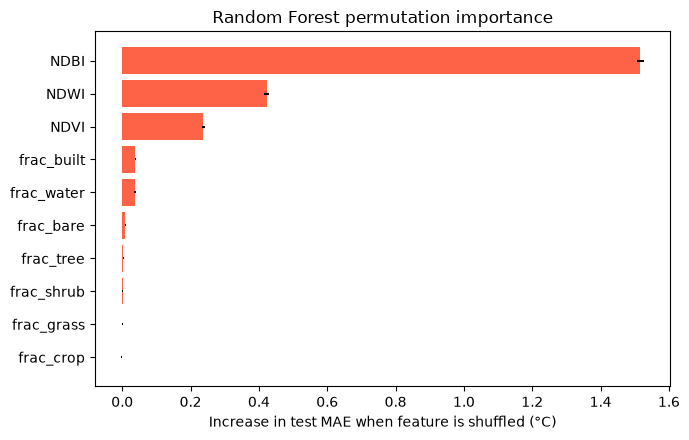

,feature,MAE_increase,sd
1,NDBI,1.517,0.011
2,NDWI,0.423,0.007
0,NDVI,0.238,0.005
7,frac_built,0.038,0.002
9,frac_water,0.038,0.002
8,frac_bare,0.009,0.002
3,frac_tree,0.003,0.002
4,frac_shrub,0.002,0.001
5,frac_grass,0.000,0.001
6,frac_crop,-0.002,0.002


In [2]:
pi = permutation_importance(rf, test[FEATURES_RF], test['LST'],
                            scoring='neg_mean_absolute_error',
                            n_repeats=10, random_state=42, n_jobs=-1)
imp = pd.DataFrame({'feature': FEATURES_RF,
                    'MAE_increase': pi.importances_mean,
                    'sd': pi.importances_std}).sort_values('MAE_increase')

plt.figure(figsize=(7, 4.5))
plt.barh(imp['feature'], imp['MAE_increase'], xerr=imp['sd'], color='tomato')
plt.xlabel('Increase in test MAE when feature is shuffled (°C)')
plt.title('Random Forest permutation importance')
plt.tight_layout(); plt.savefig(FIG + 'rf_permutation_importance.png', dpi=150); plt.show()

imp.to_csv('../outputs/rf_importance.csv', index=False)
imp.sort_values('MAE_increase', ascending=False).round(3)

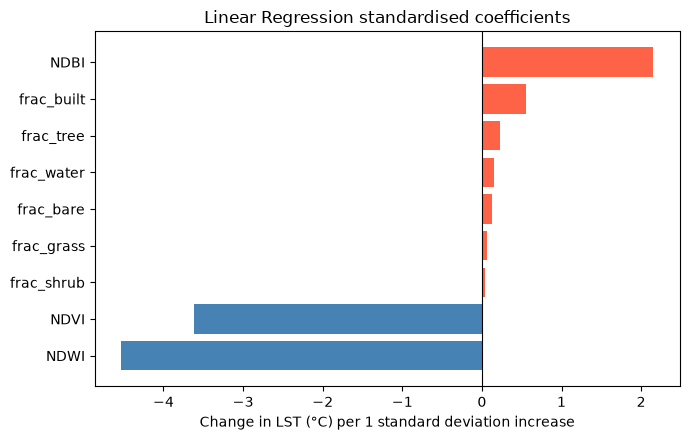

,feature,coef_per_SD
2,NDWI,-4.530
0,NDVI,-3.613
4,frac_shrub,0.045
5,frac_grass,0.063
7,frac_bare,0.124
8,frac_water,0.148
3,frac_tree,0.229
6,frac_built,0.550
1,NDBI,2.154


In [3]:
coef = pd.DataFrame({'feature': FEATURES_LR,
                     'coef_per_SD': lr.named_steps['lr'].coef_}).sort_values('coef_per_SD')

plt.figure(figsize=(7, 4.5))
plt.barh(coef['feature'], coef['coef_per_SD'],
         color=np.where(coef['coef_per_SD'] > 0, 'tomato', 'steelblue'))
plt.axvline(0, color='black', lw=0.8)
plt.xlabel('Change in LST (°C) per 1 standard deviation increase')
plt.title('Linear Regression standardised coefficients')
plt.tight_layout(); plt.savefig(FIG + 'lr_coefficients.png', dpi=150); plt.show()

coef.to_csv('../outputs/lr_coefficients.csv', index=False)
coef.round(3)

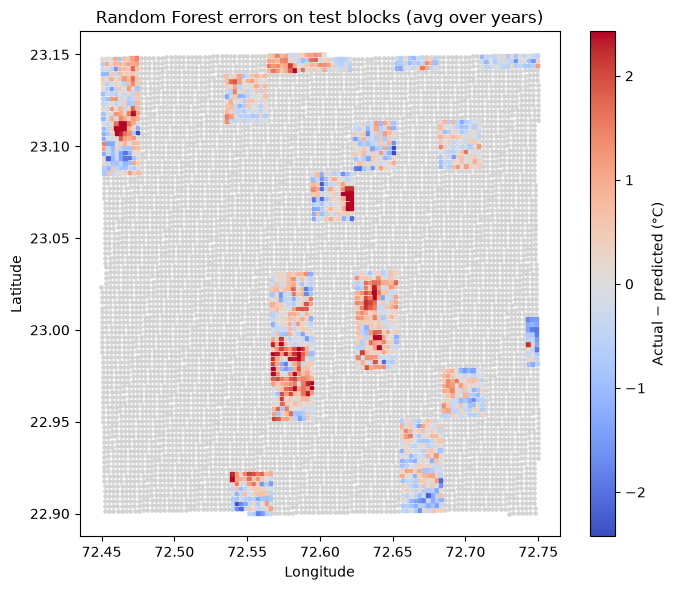

In [4]:
cell_res = preds.groupby(['latitude', 'longitude'])['resid_rf'].mean().reset_index()
lim = np.abs(cell_res['resid_rf']).quantile(0.98)

plt.figure(figsize=(7, 6))
plt.scatter(df['longitude'], df['latitude'], c='lightgrey', s=4, marker='s')   # training area
sc = plt.scatter(cell_res['longitude'], cell_res['latitude'], c=cell_res['resid_rf'],
                 cmap='coolwarm', vmin=-lim, vmax=lim, s=6, marker='s')
plt.colorbar(sc, label='Actual − predicted (°C)')
plt.xlabel('Longitude'); plt.ylabel('Latitude')
plt.title('Random Forest errors on test blocks (avg over years)')
plt.tight_layout(); plt.savefig(FIG + 'rf_residual_map.png', dpi=150); plt.show()

In [5]:
frac_cols = [c for c in FEATURES_RF if c.startswith('frac_')]
t = test.copy()
t['resid_rf'] = preds['resid_rf'].values
t['abs_err']  = t['resid_rf'].abs()
t['dominant'] = t[frac_cols].idxmax(axis=1).str.replace('frac_', '')

by_lc = t.groupby('dominant').agg(n=('abs_err', 'size'),
                                  MAE=('abs_err', 'mean'),
                                  mean_resid=('resid_rf', 'mean')).round(2)
print('Error by dominant land cover:\n', by_lc.sort_values('n', ascending=False))

t['LST_bin'] = pd.cut(t['LST'], bins=[30, 42, 45, 48, 51, 54, 60])
by_t = t.groupby('LST_bin', observed=True).agg(n=('abs_err', 'size'),
                                               MAE=('abs_err', 'mean'),
                                               mean_resid=('resid_rf', 'mean')).round(2)
print('\nError by actual LST range:\n', by_t)

by_lc.to_csv('../outputs/error_by_landcover.csv')
by_t.to_csv('../outputs/error_by_lst_range.csv')

Error by dominant land cover:
              n   MAE  mean_resid
dominant                        
crop      4662  1.32        0.00
built     3720  1.50        0.45
tree      1128  1.28       -0.07
shrub      234  1.34        0.14
water      192  1.31        0.49
bare        48  1.34        0.43
grass       12  1.22        0.32

Error by actual LST range:
              n   MAE  mean_resid
LST_bin                         
(30, 42]   404  1.28       -0.48
(42, 45]   856  1.47       -1.04
(45, 48]  3486  1.13       -0.61
(48, 51]  3742  1.16        0.39
(51, 54]  1276  2.23        2.04
(54, 60]   232  3.93        3.93


In [6]:
p = preds.copy()
rows = []
for yr, g in p.groupby('year'):
    thr_actual = g['LST'].quantile(0.90)
    actual_hot = g['LST'] >= thr_actual
    for key, name in [('lr', 'Linear Regression'), ('rf', 'Random Forest')]:
        pred_hot = g[f'pred_{key}'] >= g[f'pred_{key}'].quantile(0.90)
        hit = (actual_hot & pred_hot).sum() / actual_hot.sum()
        rows.append({'year': yr, 'model': name, 'hotspot_recall': hit})

hs = pd.DataFrame(rows)
summary = hs.groupby('model')['hotspot_recall'].agg(['mean', 'min', 'max']).round(3)
print('Share of true top-10% hottest test cells that the model also ranks in its top 10%')
print('(random guessing would give about 0.10)\n')
print(summary)
summary.to_csv('../outputs/hotspot_recall.csv')

Share of true top-10% hottest test cells that the model also ranks in its top 10%
(random guessing would give about 0.10)

                    mean    min    max
model                                 
Linear Regression  0.510  0.449  0.557
Random Forest      0.536  0.512  0.587
